**PRÁCTICA 5: ENTRENAMIENTO DE RED CONVOLUCIONAL PROFUNDA (MINI-XCEPTION)**

En este cuaderno se desarrolla el entrenamiento completo, ajuste fino y evaluación exhaustiva de una red neuronal convolucional ligera inspirada en la arquitectura **mini-Xception** (≈ 93.000 parámetros), diseñada para clasificación de emociones en tiempo real.

El entrenamiento incorpora técnicas modernas de regularización y optimización:
- Detección y aceleración en GPU con política de precisión mixta, exportando el modelo final en precisión simple para una inferencia eficiente en CPU.
- Optimizador **AdamW** con calentamiento lineal y decaimiento coseno de la tasa de aprendizaje.
- Suavizado de etiquetas y pesos de clase balanceados suavizados para gestionar el desbalance de muestras sin desestabilizar el gradiente.
- Monitorización integral mediante curvas de aprendizaje, matriz de confusión, análisis de calibración probabilística y evaluación con aumento de datos en test.

**IMPORTS NECESARIOS Y DEPENDENCIAS**

Se importan las librerías de TensorFlow/Keras para la construcción y entrenamiento de la red, bibliotecas científicas, métricas de evaluación de *scikit-learn* y las rutinas auxiliares.

In [1]:
import json, os, platform, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, top_k_accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

from comun import EMOCIONES, TAM_CNN, cargar_dataset, informe, preparar_cnn, registrar_entrenamiento

**CONFIGURACIÓN DE HIPERPARÁMETROS Y ENTORNO DE EJECUCIÓN**

Se fijan los hiperparámetros de entrenamiento (semilla aleatoria, épocas, tamaño de batch, tasas de aprendizaje máxima y mínima, paciencia y factores de regularización). Asimismo, se detecta la disponibilidad de aceleración por GPU, configurando la política de precisión mixta correspondiente y creando el directorio `informe_entrenamiento/` para almacenar las métricas generadas.

In [ ]:
# Hioperparametros
RUTA_TRAIN = "dataset/train"
RUTA_TEST = "dataset/test"
SALIDA = "modelos/cnn.keras"
DIR = Path("informe_entrenamiento"); DIR.mkdir(exist_ok=True)

SEED = 42
EPOCHS = 80
BATCH = 128
LR_MAX = 2e-3            # pico tras el calentamiento
LR_MIN = 1e-5            # final del decaimiento coseno
WARMUP = 3               # épocas de calentamiento lineal
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
PESO_CLASE_POTENCIA = 0.5 
PACIENCIA = 20
VAL_FRAC = 0.1
ARQ = dict(stem=8, bloques=(16, 32, 96, 160), n_sep=2)

# GPU
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError as e:
        print("memory_growth:", e)
USA_GPU = len(gpus) > 0
if USA_GPU:
    keras.mixed_precision.set_global_policy("mixed_float16")
else:
    print("AVISO: no se ha detectado GPU, se entrenará en CPU.")
    if sys.platform == "win32":
        print("  TensorFlow >= 2.11 no usa GPU en Windows nativo. Opciones: WSL2 "
              "(pip install tensorflow[and-cuda]), Linux, Google Colab o Kaggle.")

keras.utils.set_random_seed(SEED)

ENTORNO = {
    "python": platform.python_version(),
    "so": platform.platform(),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "gpus": [tf.config.experimental.get_device_details(g).get("device_name", str(g)) for g in gpus],
    "usa_gpu": USA_GPU,
    "politica_precision": keras.mixed_precision.global_policy().name,
    "cpus": os.cpu_count(),
}
CONFIG = dict(SEED=SEED, EPOCHS=EPOCHS, BATCH=BATCH, LR_MAX=LR_MAX, LR_MIN=LR_MIN, WARMUP=WARMUP,
              WEIGHT_DECAY=WEIGHT_DECAY, LABEL_SMOOTHING=LABEL_SMOOTHING,
              PESO_CLASE_POTENCIA=PESO_CLASE_POTENCIA, PACIENCIA=PACIENCIA, VAL_FRAC=VAL_FRAC,
              TAM_CNN=TAM_CNN, **{f"ARQ_{k}": v for k, v in ARQ.items()})
print(pd.Series(ENTORNO).to_string())

AVISO: no se ha detectado GPU, se entrenará en CPU.
  TensorFlow >= 2.11 no usa GPU en Windows nativo. Opciones: WSL2 (pip install tensorflow[and-cuda]), Linux, Google Colab o Kaggle.
python                                   3.11.5
so                    Windows-10-10.0.26300-SP0
tensorflow                               2.21.0
keras                                    3.15.1
gpus                                         []
usa_gpu                                   False
politica_precision                      float32
cpus                                         16


**CARGA Y NORMALIZACIÓN DEL CONJUNTO DE DATOS**

Se cargan las imágenes de los subdirectorios de entrenamiento y test adaptadas al tamaño de entrada de la CNN. Las imágenes se convierten a tensores de un único canal en formato `float32`, normalizando los valores de intensidad al rango $[0, 1]$.

In [3]:
t0 = time.time()
imgs_tr, ytr = cargar_dataset(RUTA_TRAIN, tam=TAM_CNN)
imgs_te, yte = cargar_dataset(RUTA_TEST, tam=TAM_CNN)
Xtr = np.array([preparar_cnn(i) for i in imgs_tr])
Xte = np.array([preparar_cnn(i) for i in imgs_te])
ytr = np.asarray(ytr).astype(int)
yte = np.asarray(yte).astype(int)
if Xtr.ndim == 3:                       # (N, H, W) -> (N, H, W, 1)
    Xtr, Xte = Xtr[..., None], Xte[..., None]
Xtr, Xte = Xtr.astype("float32"), Xte.astype("float32")
t_carga = time.time() - t0

N = len(EMOCIONES)
ytr_total = ytr.copy()
print(f"Carga y preprocesado: {t_carga:.1f} s")
print(f"Xtr {Xtr.shape} | Xte {Xte.shape} | rango [{Xtr.min():.2f}, {Xtr.max():.2f}] | "
      f"media {Xtr.mean():.3f} | std {Xtr.std():.3f}")

dataset/train: 30416 imágenes | por clase: {'angry': 3995, 'duckface': 2143, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}
dataset/test: 7558 imágenes | por clase: {'angry': 958, 'duckface': 491, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}
Carga y preprocesado: 7.4 s
Xtr (30416, 48, 48, 1) | Xte (7558, 48, 48, 1) | rango [0.00, 1.00] | media 0.501 | std 0.292


**PARTICIÓN DE VALIDACIÓN, BALANCEO DE CLASES Y AUMENTO DE DATOS**

Se reserva un 10 % estratificado del conjunto de entrenamiento para validación interna con el fin de seleccionar de forma reproducible la mejor época de los pesos. Se calculan los pesos de clase mediante ponderación suavizada para mayor igual entre los modelos y evitar el excesivo ruido en el gradiente, y se define la capa de aumento de datos con rotaciones, traslaciones, zoom y volteo horizontal.

,train_total,train,val,test,train_%,test_%,peso_balanced,peso_usado
angry,3995,3596,399,958,13.13,12.68,1.087,1.058
duckface,2143,1929,214,491,7.05,6.50,2.027,1.445
fear,4097,3687,410,1024,13.47,13.55,1.061,1.045
happy,7215,6493,722,1774,23.72,23.47,0.602,0.788
neutral,4965,4468,497,1233,16.32,16.31,0.875,0.949
sad,4830,4347,483,1247,15.88,16.50,0.900,0.962
surprise,3171,2854,317,831,10.43,10.99,1.370,1.188


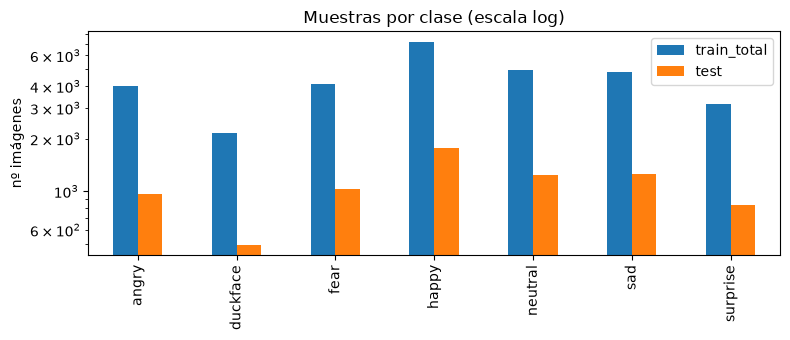

In [ ]:
# Validación para elegir la mejor época; el test queda intacto
Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=VAL_FRAC, stratify=ytr, random_state=SEED)

# Distribución de clases
df_dist = pd.DataFrame({
    "train_total": np.bincount(ytr_total, minlength=N),
    "train": np.bincount(ytr, minlength=N),
    "val": np.bincount(yva, minlength=N),
    "test": np.bincount(yte, minlength=N),
}, index=EMOCIONES)
df_dist["train_%"] = (100 * df_dist["train_total"] / df_dist["train_total"].sum()).round(2)
df_dist["test_%"] = (100 * df_dist["test"] / df_dist["test"].sum()).round(2)

# Pesos de clase suavizados
clases = np.unique(ytr)
pesos_bal = compute_class_weight("balanced", classes=clases, y=ytr)
pesos = pesos_bal ** PESO_CLASE_POTENCIA
pesos = pesos / np.average(pesos, weights=np.bincount(ytr, minlength=N))
class_weight = {int(c): float(p) for c, p in zip(clases, pesos)}
df_dist["peso_balanced"] = pesos_bal.round(3)
df_dist["peso_usado"] = pesos.round(3)

display(df_dist)
df_dist.to_csv(DIR / "distribucion_clases.csv")

fig, ax = plt.subplots(figsize=(8, 3.5))
df_dist[["train_total", "test"]].plot.bar(ax=ax, logy=True)
ax.set_title("Muestras por clase (escala log)"); ax.set_ylabel("nº imágenes"); plt.tight_layout()
fig.savefig(DIR / "distribucion_clases.png", dpi=150); plt.show()

**ARQUITECTURA DE LA RED NEURONAL**

Se construye la red convolucional basada en convoluciones separables en profundidad y conexiones residuales de salto, prescindiendo de capas densas y aplicando *Global Average Pooling* final para reducir drásticamente el número de parámetros a alrededor de 93000, evitando el sobreajuste.

In [5]:
def bloque_residual(x, filtros, n_sep=2):
    """n_sep convoluciones separables + atajo 1x1, con reducción a la mitad (stride 2)."""
    atajo = layers.Conv2D(filtros, 1, strides=2, padding="same", use_bias=False)(x)
    atajo = layers.BatchNormalization()(atajo)
    for k in range(n_sep):
        x = layers.SeparableConv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        if k < n_sep - 1:
            x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)
    return layers.add([x, atajo])


def construir_modelo(n_clases, stem=8, bloques=(16, 32, 96, 160), n_sep=2):
    entrada = keras.Input((TAM_CNN, TAM_CNN, 1))

    # El aumento de datos solo actúa al entrenar (Keras lo desactiva en predict)
    x = layers.RandomFlip("horizontal")(entrada)
    x = layers.RandomRotation(0.03)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomTranslation(0.05, 0.05)(x)

    for _ in range(2):
        x = layers.Conv2D(stem, 3, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)

    for filtros in bloques:
        x = bloque_residual(x, filtros, n_sep)

    x = layers.Conv2D(n_clases, 3, padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    salida = layers.Activation("softmax", dtype="float32")(x)   # salida siempre en fp32
    return keras.Model(entrada, salida)


modelo = construir_modelo(N, **ARQ)
modelo.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=LR_MAX, weight_decay=WEIGHT_DECAY),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=2, name="top2")],
)
modelo.summary()
N_PARAMS = modelo.count_params()
print(f"Parámetros: {N_PARAMS:,}")

lineas = []
modelo.summary(print_fn=lambda s, **k: lineas.append(s))
(DIR / "arquitectura.txt").write_text("\n".join(lineas), encoding="utf-8")

ytr_oh = keras.utils.to_categorical(ytr, N)
yva_oh = keras.utils.to_categorical(yva, N)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 48, 48, 1) │          0 │ input_layer[0][0] │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 48, 48, 1) │          0 │ random_flip[0][0] │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 48, 48, 1) │          0 │ random_rotation[… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation  │ (None, 48, 48, 1) │          0 │ random_zoom[0][0] │
│ (RandomTranslation) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 46, 46, 8) │         72 │ random_translati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 46, 46, 8) │         32 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 46, 46, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 44, 44, 8) │        576 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 44, 44, 8) │         32 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 44, 44, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 44, 44,    │        200 │ activation_1[0][… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 44, 44,    │         64 │ separable_conv2d… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 44, 44,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 44, 44,    │        400 │ activation_2[0][… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 44, 44,    │         64 │ separable_conv2d… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 22, 22,    │        128 │ activation_1[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 92,791 (362.46 KB)

 Trainable params: 90,935 (355.21 KB)

 Non-trainable params: 1,856 (7.25 KB)

Parámetros: 92,791


**ENTRENAMIENTO DEL MODELO Y PLANIFICACIÓN DE LA TASA DE APRENDIZAJE**

Se define el planificador personalizado de tasa de aprendizaje que combina calentamiento lineal durante las primeras épocas seguido de decaimiento coseno. Se compila la red, entropía cruzada categórica con suavizado de etiquetas y se ejecuta el bucle de entrenamiento guardando el mejor punto de control según la exactitud en validación.

In [ ]:
def lr_epoca(epoca):
    if epoca < WARMUP:
        return LR_MAX * (epoca + 1) / WARMUP
    p = (epoca - WARMUP) / max(1, EPOCHS - WARMUP)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + np.cos(np.pi * min(p, 1.0)))


class MetricasExtra(keras.callbacks.Callback):
    def __init__(self, Xva, yva):
        super().__init__()
        self.Xva, self.yva = Xva, yva
        self.mejor_acc, self.mejor_epoca, self.mejores_pesos = -1.0, 0, None

    def on_epoch_begin(self, epoch, logs=None):
        self.t_ini = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        logs["tiempo_s"] = time.time() - self.t_ini
        pred = self.model.predict(self.Xva, batch_size=512, verbose=0).argmax(1)
        logs["val_f1"] = float(f1_score(self.yva, pred, average="macro"))
        if logs.get("val_accuracy", -1) > self.mejor_acc:
            self.mejor_acc, self.mejor_epoca = logs["val_accuracy"], epoch + 1
            self.mejores_pesos = self.model.get_weights()
        print(f"   val_f1_macro={logs['val_f1']:.4f} | mejor val_acc={self.mejor_acc:.4f} "
              f"(época {self.mejor_epoca}) | {logs['tiempo_s']:.1f}s")


extra = MetricasExtra(Xva, yva)
callbacks = [
    extra,                                                  
    keras.callbacks.LearningRateScheduler(lr_epoca),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=PACIENCIA,
                                  restore_best_weights=False),
]

t0 = time.time()
historia = modelo.fit(Xtr, ytr_oh, validation_data=(Xva, yva_oh), epochs=EPOCHS,
                      batch_size=BATCH, class_weight=class_weight, callbacks=callbacks, verbose=2)
t_entreno = time.time() - t0
print(f"\nEntrenamiento: {t_entreno:.1f} s ({t_entreno/len(historia.epoch):.1f} s/época, "
      f"{len(historia.epoch)} épocas ejecutadas)")

# Conseguimos la mejor epoca
modelo.set_weights(extra.mejores_pesos)
print(f"Pesos restaurados de la época {extra.mejor_epoca} (val_accuracy={extra.mejor_acc:.4f})")

Epoch 1/80
   val_f1_macro=0.0489 | mejor val_acc=0.1387 (época 1) | 52.3s
214/214 - 54s - 253ms/step - accuracy: 0.3109 - loss: 1.7878 - top2: 0.4921 - val_accuracy: 0.1387 - val_loss: 2.0136 - val_top2: 0.2936 - tiempo_s: 52.3484 - val_f1: 0.0489 - learning_rate: 6.6667e-04
Epoch 2/80
   val_f1_macro=0.1894 | mejor val_acc=0.2344 (época 2) | 42.7s
214/214 - 44s - 204ms/step - accuracy: 0.4037 - loss: 1.6359 - top2: 0.5874 - val_accuracy: 0.2344 - val_loss: 1.8595 - val_top2: 0.4126 - tiempo_s: 42.6802 - val_f1: 0.1894 - learning_rate: 0.0013
Epoch 3/80
   val_f1_macro=0.4069 | mejor val_acc=0.4122 (época 3) | 40.7s
214/214 - 42s - 195ms/step - accuracy: 0.4547 - loss: 1.5438 - top2: 0.6418 - val_accuracy: 0.4122 - val_loss: 1.6464 - val_top2: 0.6075 - tiempo_s: 40.7206 - val_f1: 0.4069 - learning_rate: 0.0020
Epoch 4/80
   val_f1_macro=0.3189 | mejor val_acc=0.4122 (época 3) | 43.5s
214/214 - 44s - 208ms/step - accuracy: 0.4861 - loss: 1.4781 - top2: 0.6757 - val_accuracy: 0.3120 - v

**GENERACIÓN Y EXPORTACIÓN DE LAS CURVAS DE APRENDIZAJE**

Se procesa el historial de entrenamiento para graficar la evolución de la función de pérdida, la tasa de acierto y la métrica F1-score tanto en entrenamiento como en validación, guardando las curvas en `curvas_entrenamiento.png`.

,accuracy,loss,top2,val_accuracy,val_loss,val_top2,tiempo_s,val_f1,learning_rate,gap_acc
epoca,,,,,,,,,,
71,0.7545,0.9811,0.8983,0.6246,1.2634,0.7913,48.0626,0.6299,0.0001,0.1299
72,0.7529,0.9819,0.8996,0.6272,1.2594,0.7916,48.9631,0.6348,0.0001,0.1256
73,0.7531,0.9816,0.8975,0.6269,1.2627,0.7916,46.6871,0.6342,0.0001,0.1262
74,0.7528,0.9794,0.9002,0.6249,1.2588,0.7906,46.3864,0.6320,0.0001,0.1279
75,0.7575,0.9753,0.9020,0.6282,1.2575,0.7939,46.6011,0.6351,0.0000,0.1293
76,0.7593,0.9722,0.9014,0.6282,1.2587,0.7919,46.8105,0.6350,0.0000,0.1311
77,0.7615,0.9721,0.9019,0.6282,1.2608,0.7919,48.5224,0.6353,0.0000,0.1333
78,0.7546,0.9799,0.8969,0.6266,1.2613,0.7922,46.8850,0.6334,0.0000,0.1281
79,0.7585,0.9751,0.9026,0.6279,1.2611,0.7926,46.3888,0.6348,0.0000,0.1307


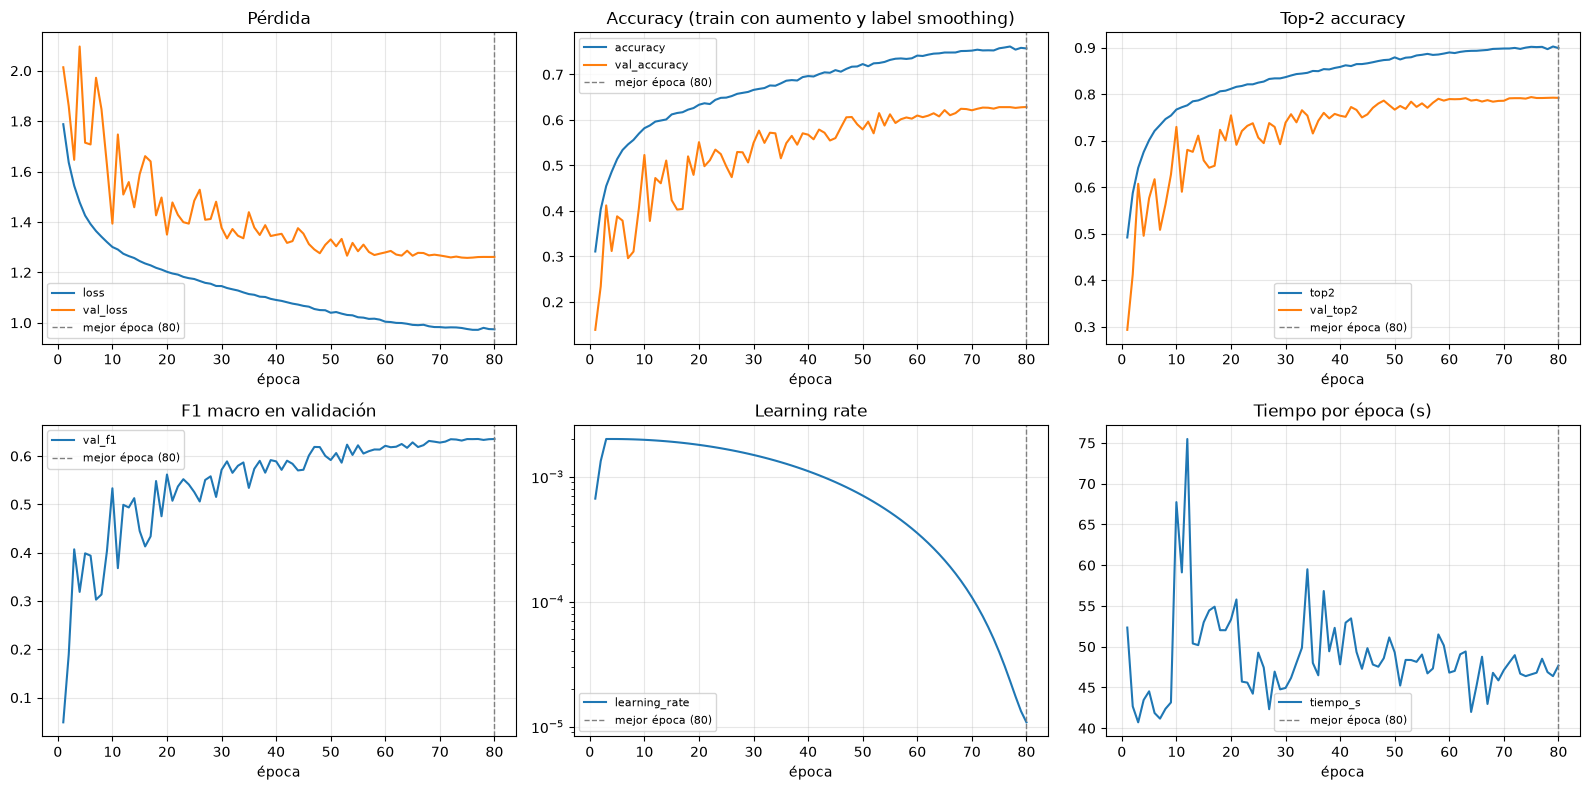

epocas_ejecutadas                  80
mejor_epoca                        80
val_accuracy_mejor           0.628534
val_f1_en_mejor               0.63521
val_loss_min                 1.257519
val_loss_min_epoca                 75
train_acc_ultima_epoca       0.757215
train_acc_en_mejor           0.757215
parada_temprana                 False
tiempo_total_s            3994.917434
tiempo_medio_epoca_s        48.783876


In [7]:
hist = pd.DataFrame(historia.history)
hist.index = np.arange(1, len(hist) + 1); hist.index.name = "epoca"
hist["gap_acc"] = hist["accuracy"] - hist["val_accuracy"]
hist.to_csv(DIR / "historia.csv")
display(hist.round(4).tail(10))

mejor = extra.mejor_epoca
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
def curva(a, cols, titulo, ylabel=None):
    for c in cols:
        a.plot(hist.index, hist[c], label=c)
    a.axvline(mejor, color="gray", ls="--", lw=1, label=f"mejor época ({mejor})")
    a.set_title(titulo); a.set_xlabel("época"); a.grid(alpha=.3); a.legend(fontsize=8)
    if ylabel: a.set_ylabel(ylabel)
curva(ax[0, 0], ["loss", "val_loss"], "Pérdida")
curva(ax[0, 1], ["accuracy", "val_accuracy"], "Accuracy (train con aumento y label smoothing)")
curva(ax[0, 2], ["top2", "val_top2"], "Top-2 accuracy")
curva(ax[1, 0], ["val_f1"], "F1 macro en validación")
curva(ax[1, 1], ["learning_rate"], "Learning rate"); ax[1, 1].set_yscale("log")
curva(ax[1, 2], ["tiempo_s"], "Tiempo por época (s)")
plt.tight_layout(); fig.savefig(DIR / "curvas_entrenamiento.png", dpi=150); plt.show()

resumen_entreno = {
    "epocas_ejecutadas": len(hist),
    "mejor_epoca": int(mejor),
    "val_accuracy_mejor": float(extra.mejor_acc),
    "val_f1_en_mejor": float(hist.loc[mejor, "val_f1"]),
    "val_loss_min": float(hist["val_loss"].min()), "val_loss_min_epoca": int(hist["val_loss"].idxmin()),
    "train_acc_ultima_epoca": float(hist["accuracy"].iloc[-1]),
    "train_acc_en_mejor": float(hist.loc[mejor, "accuracy"]),
    "parada_temprana": bool(len(hist) < EPOCHS),
    "tiempo_total_s": float(t_entreno), "tiempo_medio_epoca_s": float(hist["tiempo_s"].mean()),
}
print(pd.Series(resumen_entreno).to_string())

**RECONSTRUCCIÓN DEL MODELO FINAL EN PRECISIÓN SIMPLE**

Se reasigna la política global de precisión a `float32` y se reconstruye la arquitectura cargando los pesos de la mejor época obtenida.

In [ ]:
keras.mixed_precision.set_global_policy("float32")
modelo_final = construir_modelo(N, **ARQ)
modelo_final.set_weights(modelo.get_weights())

# Comprobación: fp16 vs fp32 dan las mismas predicciones
d = np.abs(modelo.predict(Xte[:512], verbose=0) - modelo_final.predict(Xte[:512], verbose=0))
print(f"Diferencia máx. de probabilidad modelo entrenado vs fp32: {d.max():.5f}")

def probs(m, X, tta=False):
    p = m.predict(X, batch_size=512, verbose=0)
    if tta:                                   # promedio con la imagen volteada
        p = 0.5 * (p + m.predict(X[:, :, ::-1, :], batch_size=512, verbose=0))
    return p

IDX_DUCK = EMOCIONES.index("duckface") if "duckface" in EMOCIONES else None

def metricas(y, p):
    pred = p.argmax(1)
    m = {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro"),
        "f1_weighted": f1_score(y, pred, average="weighted"),
        "top2": top_k_accuracy_score(y, p, k=2, labels=np.arange(N)),
    }
    if IDX_DUCK is not None:                  # solo las 7 emociones de FER-2013
        k = y != IDX_DUCK
        m["accuracy_sin_duckface"] = accuracy_score(y[k], pred[k])
    return m

t0 = time.time(); p_te = probs(modelo_final, Xte); t_pred = time.time() - t0
p_te_tta = probs(modelo_final, Xte, tta=True)
p_tr, p_va = probs(modelo_final, Xtr), probs(modelo_final, Xva)    # sin aumento de datos

tabla = pd.DataFrame({
    "train (limpio)": metricas(ytr, p_tr), "val": metricas(yva, p_va),
    "test": metricas(yte, p_te), "test + TTA(flip)": metricas(yte, p_te_tta),
}).T
display(tabla.round(4))
tabla.to_csv(DIR / "metricas_globales.csv")
print(f"Brecha train(limpio) - test: {tabla.loc['train (limpio)', 'accuracy'] - tabla.loc['test', 'accuracy']:+.4f}  "
      f"(>0 grande = sobreajuste; ~0 con accuracy baja = infraajuste)")

Diferencia máx. de probabilidad modelo entrenado vs fp32: 0.00000


,accuracy,balanced_accuracy,f1_macro,f1_weighted,top2,accuracy_sin_duckface
train (limpio),0.7240,0.7283,0.7301,0.7247,0.8840,0.7130
val,0.6285,0.6309,0.6352,0.6302,0.7922,0.6146
test,0.6171,0.6204,0.6258,0.6190,0.7974,0.6051
test + TTA(flip),0.6422,0.6438,0.6493,0.6433,0.8128,0.6315


Brecha train(limpio) - test: +0.1069  (>0 grande = sobreajuste; ~0 con accuracy baja = infraajuste)


**EVALUACIÓN, MATRIZ DE CONFUSIÓN Y PARES DE ERROR FRECUENTES**

Se evalúa el rendimiento del modelo sobre el conjunto de test independiente, calculando la matriz de confusión normalizada, el informe detallado por clase de precisión, recall y F1-score, y extrayendo los 10 pares de emociones que concentran la mayor confusión.

              precision    recall  f1-score   support

       angry       0.49      0.57      0.53       958
    duckface       0.96      0.79      0.87       491
        fear       0.41      0.44      0.42      1024
       happy       0.82      0.81      0.81      1774
     neutral       0.54      0.57      0.56      1233
         sad       0.50      0.42      0.46      1247
    surprise       0.72      0.74      0.73       831

    accuracy                           0.62      7558
   macro avg       0.64      0.62      0.63      7558
weighted avg       0.62      0.62      0.62      7558

Matriz de confusión (filas = real, columnas = predicho):
[[ 550    1  137   44  104   94   28]
 [  11  388    8   29   19   32    4]
 [ 151    3  449   52  109  166   94]
 [  65    5   62 1430  110   50   52]
 [ 128    5  121   78  707  162   32]
 [ 182    2  216   71  222  526   28]
 [  30    0  108   32   27   20  614]]

Accuracy test: 0.6171 | F1 macro: 0.6258
Tiempo de entrenamiento: 3994.9 s
Inf

,precision,recall,f1-score,support
angry,0.492,0.574,0.530,958.000
duckface,0.960,0.790,0.867,491.000
fear,0.408,0.438,0.423,1024.000
happy,0.824,0.806,0.815,1774.000
neutral,0.545,0.573,0.559,1233.000
sad,0.501,0.422,0.458,1247.000
surprise,0.721,0.739,0.730,831.000
accuracy,0.617,0.617,0.617,0.617
macro avg,0.636,0.620,0.626,7558.000
weighted avg,0.624,0.617,0.619,7558.000


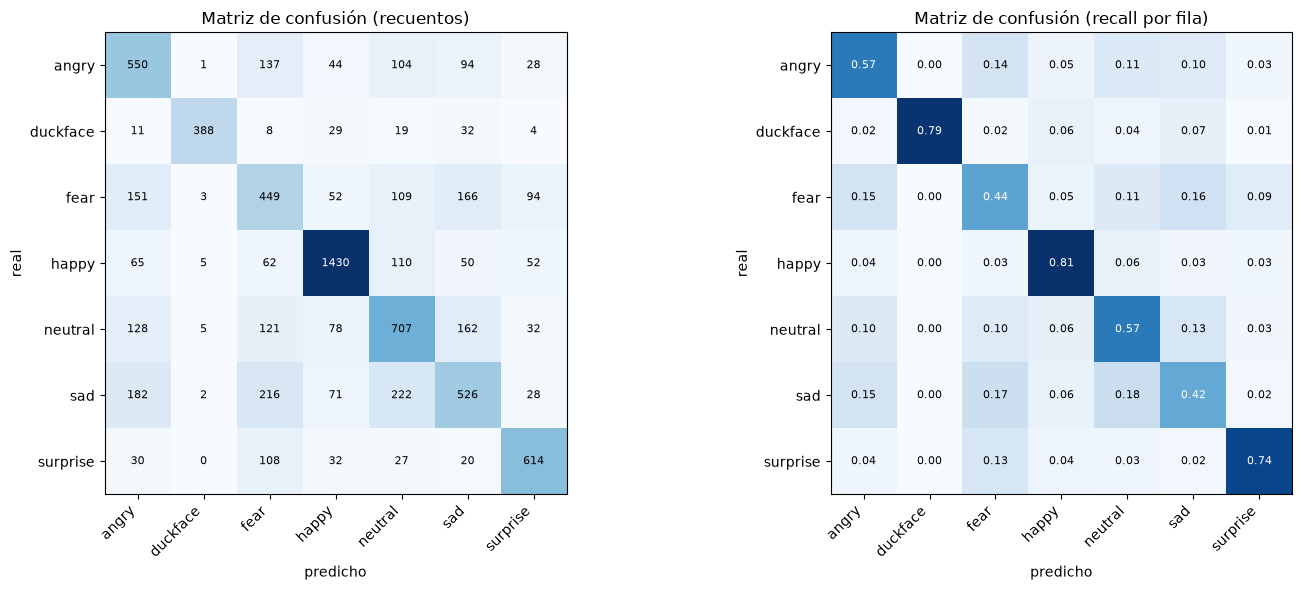

,real,predicho,n,% de la clase real
0,sad,neutral,222,17.8
1,sad,fear,216,17.3
2,sad,angry,182,14.6
3,fear,sad,166,16.2
4,neutral,sad,162,13.1
5,fear,angry,151,14.7
6,angry,fear,137,14.3
7,neutral,angry,128,10.4
8,neutral,fear,121,9.8
9,happy,neutral,110,6.2


In [ ]:
pred = p_te.argmax(1)
informe(yte, pred, t_entreno, t_pred)

# Informe por clase
rep = pd.DataFrame(classification_report(yte, pred, labels=np.arange(N), target_names=EMOCIONES,
                                         output_dict=True, zero_division=0)).T
rep.to_csv(DIR / "informe_por_clase.csv"); display(rep.round(3))

# Matriz de confusión
cm = confusion_matrix(yte, pred, labels=np.arange(N))
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, M, t, fmt in [(ax[0], cm, "Matriz de confusión (recuentos)", "d"),
                     (ax[1], cmn, "Matriz de confusión (recall por fila)", ".2f")]:
    im = a.imshow(M, cmap="Blues"); a.set_title(t)
    a.set_xticks(range(N)); a.set_xticklabels(EMOCIONES, rotation=45, ha="right")
    a.set_yticks(range(N)); a.set_yticklabels(EMOCIONES)
    a.set_xlabel("predicho"); a.set_ylabel("real")
    for i in range(N):
        for j in range(N):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center",
                   color="white" if M[i, j] > M.max() / 2 else "black", fontsize=8)
plt.tight_layout(); fig.savefig(DIR / "matriz_confusion.png", dpi=150); plt.show()

# Confusiones más frecuentes
pares = pd.DataFrame([(EMOCIONES[i], EMOCIONES[j], int(cm[i, j]), cm[i, j] / max(cm[i].sum(), 1))
                      for i in range(N) for j in range(N) if i != j],
                     columns=["real", "predicho", "n", "% de la clase real"])
pares = pares.sort_values("n", ascending=False).head(10).reset_index(drop=True)
pares["% de la clase real"] = (100 * pares["% de la clase real"]).round(1)
display(pares); pares.to_csv(DIR / "confusiones_top.csv", index=False)

**CALIBRACIÓN PROBABILÍSTICA Y ERROR DE CALIBRACIÓN ESPERADO**

Se analiza la fiabilidad de las probabilidades predichas por la red evaluando si la confianza asignada a cada predicción coincide con su probabilidad real de acierto. Se computa el error de calibración esperado y se obtiene el gráfico de calibración correspondiente.

,rango_confianza,n,confianza_media,accuracy
0,0.1-0.2,1,0.198,1.000
1,0.2-0.3,270,0.270,0.289
2,0.3-0.4,1094,0.356,0.346
3,0.4-0.5,1290,0.450,0.446
4,0.5-0.6,1099,0.548,0.531
5,0.6-0.7,981,0.649,0.634
6,0.7-0.8,866,0.750,0.767
7,0.8-0.9,957,0.852,0.844
8,0.9-1.0,1000,0.946,0.953


ECE: 0.0111 | confianza media aciertos: 0.693 | fallos: 0.504


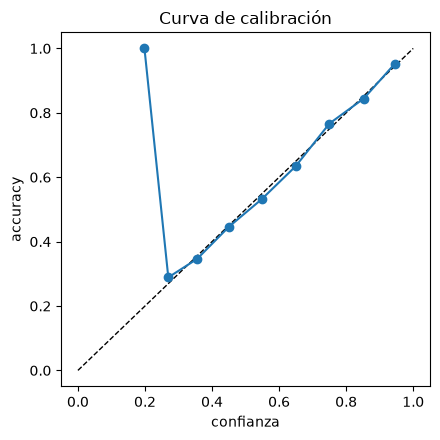

In [ ]:
# Calibración 
conf, ok = p_te.max(1), (pred == yte)
bins = np.linspace(0, 1, 11)
filas, ece = [], 0.0
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum():
        filas.append((f"{lo:.1f}-{hi:.1f}", int(m.sum()), conf[m].mean(), ok[m].mean()))
        ece += m.mean() * abs(conf[m].mean() - ok[m].mean())
cal = pd.DataFrame(filas, columns=["rango_confianza", "n", "confianza_media", "accuracy"])
display(cal.round(3)); cal.to_csv(DIR / "calibracion.csv", index=False)
print(f"ECE: {ece:.4f} | confianza media aciertos: {conf[ok].mean():.3f} | fallos: {conf[~ok].mean():.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(cal["confianza_media"], cal["accuracy"], "o-")
ax.set_xlabel("confianza"); ax.set_ylabel("accuracy"); ax.set_title("Curva de calibración")
plt.tight_layout(); fig.savefig(DIR / "calibracion.png", dpi=150); plt.show()

**BENCHMARK DE LATENCIA DE INFERENCIA EN CPU**

Se mide el tiempo medio de respuesta por fotograma en CPU simulando las condiciones de la webcam, comparando la ejecución en modo dinámico frente a la optimización mediante grafo estático.

In [11]:
x1 = Xte[:1]
with tf.device("/CPU:0"):
    modelo_final(x1, training=False)                       # calentamiento
    t0 = time.time()
    for _ in range(100):
        modelo_final(x1, training=False)
    ms_eager = (time.time() - t0) * 10

    @tf.function
    def inferir(x):
        return modelo_final(x, training=False)
    inferir(tf.constant(x1)); inferir(tf.constant(x1))     # trazado + calentamiento
    t0 = time.time()
    for _ in range(200):
        inferir(tf.constant(x1))
    ms_graph = (time.time() - t0) * 5
print(f"CPU, una cara, eager:        {ms_eager:.2f} ms")
print(f"CPU, una cara, tf.function:  {ms_graph:.2f} ms   <- usar esto en la app en tiempo real")
print(f"Inferencia por lotes (dispositivo de entrenamiento): {1000 * t_pred / len(Xte):.3f} ms/imagen")

CPU, una cara, eager:        42.76 ms
CPU, una cara, tf.function:  3.71 ms   <- usar esto en la app en tiempo real
Inferencia por lotes (dispositivo de entrenamiento): 0.417 ms/imagen


**SERIALIZACIÓN DEL MODELO FINAL Y GUARDADO DEL RESUMEN**

Se guarda el modelo final en formato Keras nativo y se genera un archivo `resumen.json` que recoge de forma estructurada los hiperparámetros, métricas globales, tiempos de ejecución y configuración del entorno.

In [12]:
modelo_final.save(SALIDA)
print("Modelo (fp32) guardado en", SALIDA)

def _j(o):
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

resumen = {
    "entorno": ENTORNO, "configuracion": CONFIG, "parametros": int(N_PARAMS),
    "clases": EMOCIONES, "distribucion": df_dist.to_dict(),
    "class_weight_usado": class_weight,
    "entrenamiento": resumen_entreno,
    "metricas_globales": tabla.to_dict(),
    "ece": float(ece),
    "inferencia_cpu_ms_eager": float(ms_eager), "inferencia_cpu_ms_tf_function": float(ms_graph),
    "tiempo_carga_datos_s": float(t_carga),
}
registrar_entrenamiento(SALIDA, t_entreno, ms_imagen=float(ms_graph), accuracy=float(tabla.loc["test", "accuracy"]), f1_macro=float(tabla.loc["test", "f1_macro"]))
(DIR / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=_j), encoding="utf-8")

print("\nArchivos generados en", DIR.resolve())
for f in sorted(DIR.iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size/1024:8.1f} KB")

t = tabla.loc["test"]; tt = tabla.loc["test + TTA(flip)"]
print(f"""
================= RESUMEN =================
Dispositivo: {'GPU ' + str(ENTORNO['gpus']) if USA_GPU else 'CPU'} | precisión de entrenamiento: {ENTORNO['politica_precision']}
Parámetros: {N_PARAMS:,} | épocas ejecutadas: {len(hist)} | mejor época: {mejor}
Tiempo de entrenamiento: {t_entreno:.0f} s ({hist['tiempo_s'].mean():.1f} s/época)
Accuracy  train(limpio) {tabla.loc['train (limpio)','accuracy']:.4f} | val {tabla.loc['val','accuracy']:.4f} | test {t['accuracy']:.4f} | test+TTA {tt['accuracy']:.4f}
F1 macro  test {t['f1_macro']:.4f} | test+TTA {tt['f1_macro']:.4f}
===========================================""")

Modelo (fp32) guardado en cnn.keras

Archivos generados en C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P5\P5\informe_entrenamiento
  arquitectura.txt                     20.2 KB
  calibracion.csv                       0.4 KB
  calibracion.png                      35.3 KB
  confusiones_top.csv                   0.2 KB
  curvas_entrenamiento.png            262.4 KB
  distribucion_clases.csv               0.4 KB
  distribucion_clases.png              33.0 KB
  historia.csv                         15.4 KB
  informe_por_clase.csv                 0.8 KB
  matriz_confusion.png                126.8 KB
  metricas_globales.csv                 0.6 KB
  resumen.json                          4.3 KB

================= RESUMEN =================
Dispositivo: CPU | precisión de entrenamiento: float32
Parámetros: 92,791 | épocas ejecutadas: 80 | mejor época: 80
Tiempo de entrenamiento: 3995 s (48.8 s/época)
Accuracy  train(limpio) 0.7240 | val 0.6285 | test 0.6171 | test+TTA 0.6422
F1 ma

**ANÁLISIS Y CONCLUSIONES DEL ENTRENAMIENTO**

- **Brecha train / val / test**: accuracy 0,724 en train frente a 0,629 en validación y 0,617 en test. Validación y test son muy parecidos, así que la validación es un buen estimador; la brecha train–test de ≈ 0,11 indica un **sobreajuste moderado**.
- **Convergencia**: la mejor época fue la **última 80**, por lo que la validación todavía mejoraba lentamente pudiendo darse el caso que con más epocas se podría mejorar levemente el resultado.
- **Matriz de confusión**: los errores se concentran en las emociones "negativas" y la neutral: `sad` se confunde con `neutral` 17,8 %, `fear` 17,3 % y `angry` 14,6 %; `fear` con `sad` 16,2 % y `angry` 14,7 %. Son también las clases con etiquetas más ambiguas en FER-2013.
- **Clases fáciles**: las clases que mejor a detectado son `happy`, `surprise` y `duckface`. Aunque se debe tener en cuenta que parte de las imagenes de duckface provienen de otro dominio.
- **TTA**: promediar la predicción con la imagen volteada sube la accuracy de 0,617 a 0,642 a cambio de duplicar el coste.
- **Calibración**: La metríca ECE se quedo alrededor del 0.11, la confianza que da la red se corresponde muy bien con su tasa de acierto, lo que permite usar la probabilidad para suavizar y mostrar confianza en la webcam.
- **Eficiencia**: 92.791 parámetros y alrededor de 3,7 ms por cara en CPU con `tf.function`, más que suficiente para tiempo real.